# Lab 06: How to answer from documents with citations

**CPU | API key: `OPENAI_API_KEY` | Follows: Day 1 D1-M08, steps 8.1 to 8.7 (slides 251–296)**

## Goal

The copilot can search the support handbook, but search alone answers nothing: it returns the three nearest
passages, even for a question no policy covers. In this lab you connect the search to the chat model so that the
copilot answers from the passages, names the file each rule came from and says so when the handbook is silent, and
you check every answer in code. The moment that teaches it: asked whether Chinook matches a lower price, which no
policy covers, the copilot (`gpt-4o-mini`, in every one of our runs) invents *we do not match lower prices*, cites a
real file it retrieved, and passes the citation check. A citation shows where the model looked, not that the source says it; a quote for each claim,
checked in code, closes that gap.

## What you will learn

- How to answer from retrieved passages two ways: retrieve in your own code (two-step RAG) or give the model a
  retriever tool (agentic RAG), and what each costs in model calls.
- How to build a retriever tool that also returns its hits as data (`response_format="content_and_artifact"`), so
  your code knows exactly which files the model was given.
- How to check a cited answer in code: every cited file was retrieved, the reply abstains when no policy covers the
  question, and no phone number was made up.
- How to test abstention with a question no policy covers, and how to notice when the agent skipped its search.
- Why a real citation does not prove a claim, and how to make each claim carry a quote that your code can check.
- When sending the whole handbook beats retrieval, measured in tokens on the same questions.

| Part | What you do | Calls to OpenAI |
|---|---|---|
| A | Retrieve three passages, answer from them in one call, check the citations | 1 |
| B | Give the copilot a retriever tool; return its hits as data | 2 |
| C | Ask a question no policy covers, three times | 6 |
| D | Ask for the manager's personal number, three times; check each cited sentence | 3 to 6 (3 when the agent skips its search) |
| E | Mark three cited answers, then make every claim carry a quote your code checks | 4 |
| F | Send the whole handbook instead, and choose a route for the copilot | 6 |

Each search also embeds the query with `EMBED_MODEL` (about 12 embedding calls in all). The whole lab costs
well under one US cent with `gpt-4o-mini`.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


Every part calls `CHAT_MODEL`, and every search embeds its query with `EMBED_MODEL`.

The picture shows the two ways this lab wires retrieval in. On the left, your code searches with the rep's words and
sends the passages with the question: one model call. On the right, the model asks for a search with words it
chooses, your code runs it, and the model answers in a second call. Both end in an answer that cites policy files,
and both answers go through the same checks in your code.

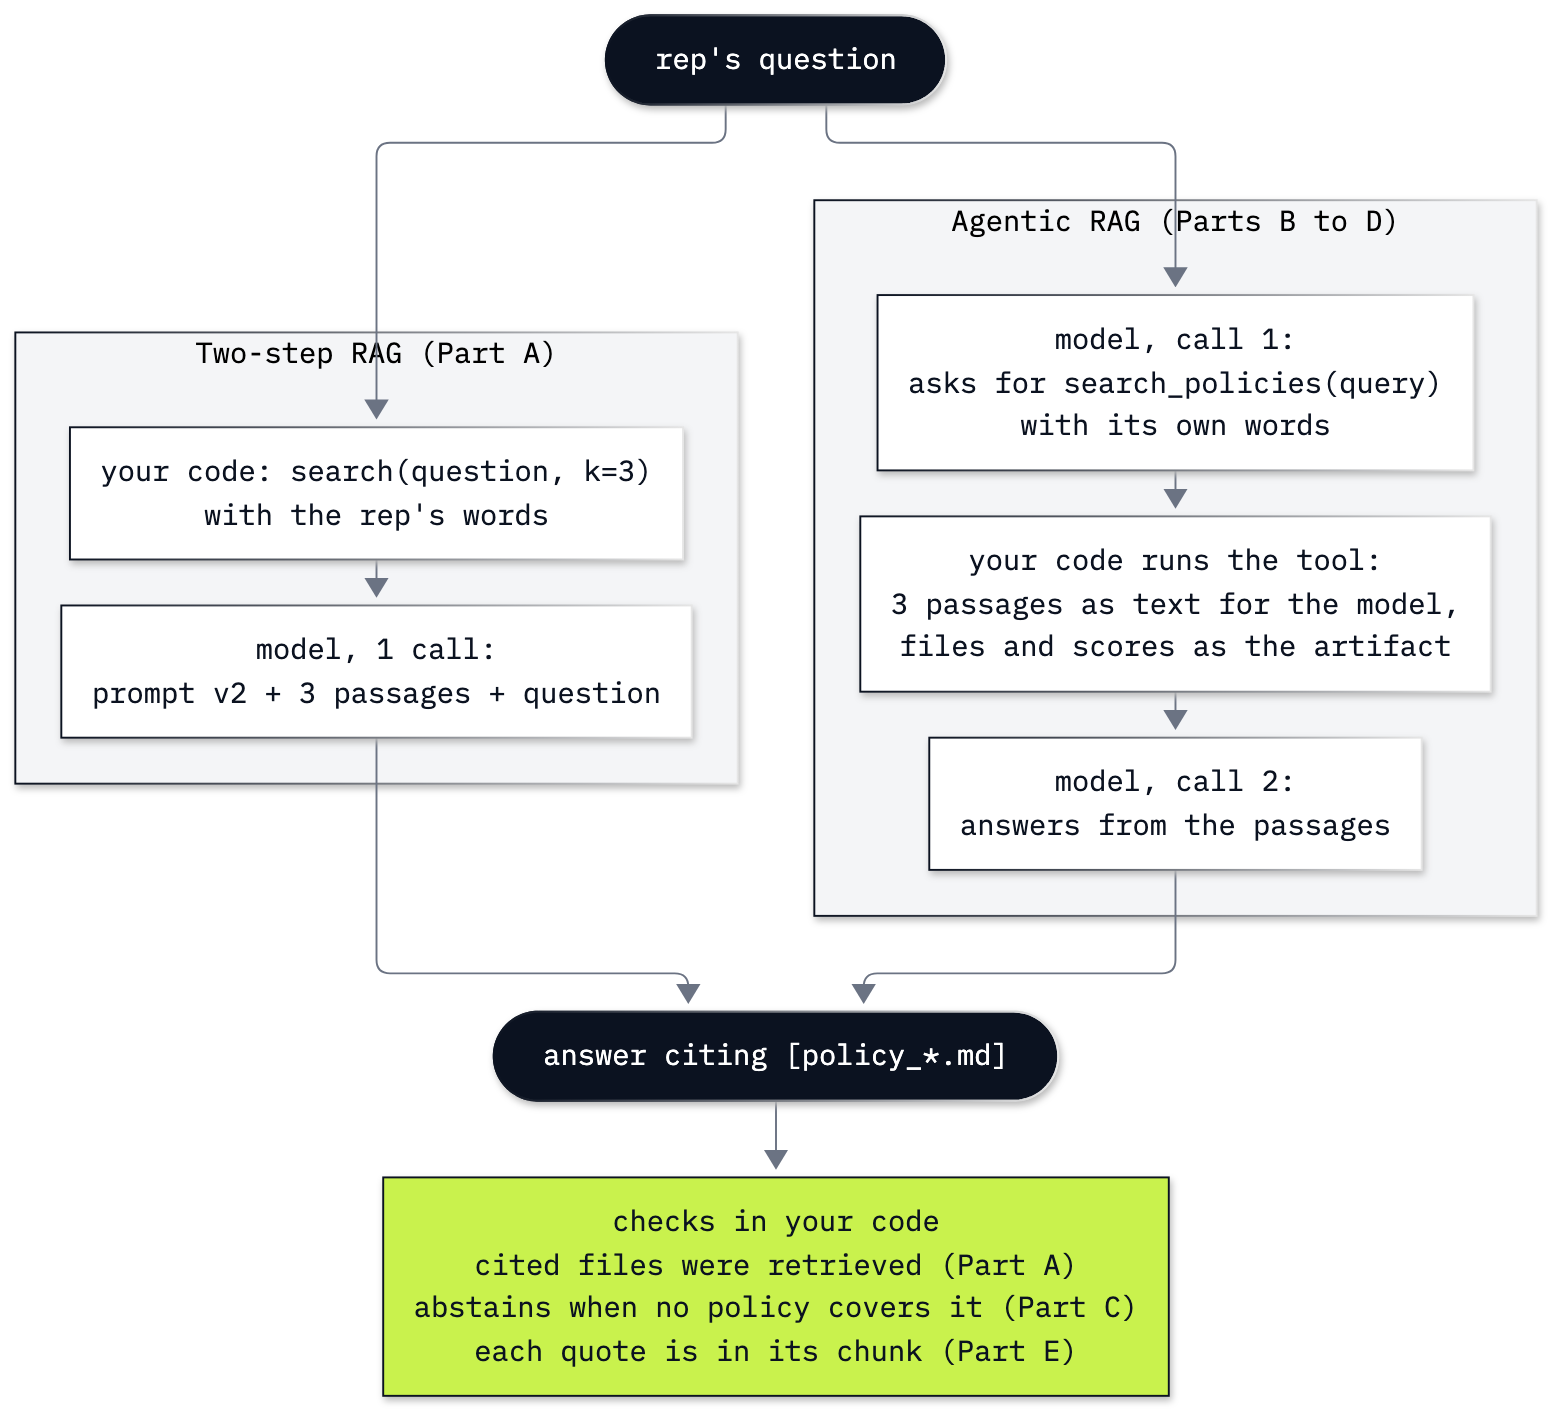

In [3]:
from IPython.display import Image
Image(filename=ROOT / "06_RAG_Citations_Abstention" / "resources" / "lab06_rag_routes.png", width=640)

---

## Load the handbook index

Search by meaning needs two ideas. An **embedding** is a list of numbers that an embedding model
(`text-embedding-3-small`, `EMBED_MODEL` in `models.env`) computes from a text, so that texts with similar meanings
get similar numbers. A **vector index** stores one embedding per chunk of text and, given the embedding of a question,
returns the chunks whose numbers are closest; FAISS is a library that does this search on your machine. Here the
support handbook is split into 20 chunks, one per policy, and each chunk's embedding is saved in a FAISS index.

Lab 05 builds that index step by step. This lab starts from a prebuilt copy in `data/index/`, built from the same
handbook, and the functions Lab 05 wrote to build and search it are kept in `shared/copilot.py`.

`load_index()` reads two files: `handbook.faiss` (the vectors) and `chunks.json` (the text, since FAISS stores no
text). A FAISS file is binary data that your code trusts, so load only index files you wrote yourself or that come
with a repository you trust, as this one does.

In [4]:
from shared.copilot import load_index, search

index, chunks = load_index()
print(index.ntotal, "chunks of", index.d, "numbers each")
print([chunk["source"] for chunk in chunks][:4], "...")

20 chunks of 1536 numbers each
['policy_accounts.md', 'policy_cancellations.md', 'policy_damaged_media.md', 'policy_data_retention.md'] ...


Each chunk keeps its policy text and the file it came from. That file name is what the copilot will cite. Here is
the refunds chunk, which the first question needs.

In [5]:
chunk_text = {chunk["source"]: chunk["text"] for chunk in chunks}
print(chunk_text["policy_refunds.md"])

## Refunds
Source: policy_refunds.md  
Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.  
Partial refunds are allowed when only some tracks on a multi-disc set are defective.  
We do not refund because a customer changed their mind about a digital purchase.  
Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.


`search(query, k=3)` embeds the query with `EMBED_MODEL`, compares it with the 20 chunk vectors and returns the three
closest as `(score, chunk)` pairs. The score is the cosine similarity: higher means closer in meaning, but it is not
a probability.

In [6]:
question = "A customer was charged twice for the same album on the same day. What do we do?"
hits = search(question, k=3)
for score, chunk in hits:
    print(f"{score:.4f}  {chunk['source']}")

0.4595  policy_refunds.md
0.4195  policy_damaged_media.md
0.3855  policy_digital_downloads.md


The refunds policy comes first, and it holds the rule for duplicate charges. The other two are close in meaning (a damaged album, a digital album) but say nothing about being charged twice. The index is prebuilt and only your question is embedded now, so your scores should match these to the third decimal.

---

## Part A: Two-step RAG

**RAG** (retrieval-augmented generation) retrieves relevant text when a question arrives and puts it in the prompt,
so that the model answers from it. Three rules make the answer something a rep can check:

- **grounding**: answer only from the passages sent in this turn, not from what the model remembers from training;
- **citation**: after each rule, name the file it came from, in square brackets, such as `[policy_refunds.md]`;
- **abstention**: when no passage answers the question, say that the handbook does not cover it instead of guessing.

Prompt v2 (`shared/prompts/copilot_system_v2.md`) asks for all three. Compared with v1, four instruction lines
changed: search before answering, cite the file, abstain, and the citation moved out of the first-sentence rule. Read
the instructions and the two examples.

In [7]:
prompt_file = ROOT / "shared" / "prompts" / "copilot_system_v2.md"
PROMPT_V2 = prompt_file.read_text(encoding="utf-8").split("-->", 1)[1].strip()
print(PROMPT_V2)

# Identity
You are the Chinook support copilot. You help Chinook's support representatives (reps) answer customer emails. You talk to the rep, not to the customer.

# Instructions
- Before you answer any question about shop rules, call search_policies, unless handbook passages are already in the message. Answer only from those passages.
- After each rule you use, name its source file in square brackets, for example [policy_refunds.md].
- If the passages do not answer the question, say that the handbook does not cover it and suggest the rep asks the support manager. Do not guess.
- Start with the answer in one sentence. Keep the whole reply under 80 words.
- When the rep needs wording for the customer, give one short, polite reply in plain English that the rep can paste into an email.
- Escalate to the support manager when a refund over 100 dollars is requested, when the same customer has three open tickets, or when the rep wants to override a written policy.
- Never invent contact deta

**Two-step RAG** means your code does the retrieval, every time, before the model is called:

1. retrieve: search with the rep's own words and take the top 3;
2. generate: send prompt v2, the passages and the question in one call.

First join the three passages into one block of text, each starting with its file in square brackets. The brackets
give the model the exact name to cite.

In [8]:
passages = "\n\n".join(f"[{chunk['source']}]\n{chunk['text']}" for score, chunk in hits)
print(passages)

[policy_refunds.md]
## Refunds
Source: policy_refunds.md  
Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.  
Partial refunds are allowed when only some tracks on a multi-disc set are defective.  
We do not refund because a customer changed their mind about a digital purchase.  
Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.

[policy_damaged_media.md]
## Damaged media
Source: policy_damaged_media.md  
If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.  
If the same title arrives damaged twice, offer a refund instead of a third copy.

[policy_digital_downloads.md]
## Digital downloads
Source: policy_digital_downloads.md  
A digital album is available for download for 90 days after purchase. After that

Now the one model call. The client comes from `chat_model()`, which reads `CHAT_MODEL` from `models.env` (Lab 03
does the same).

In [9]:
from shared.settings import chat_model

model = chat_model(settings)
reply = model.invoke([
    ("system", PROMPT_V2),
    ("user", f"Handbook passages:\n{passages}\n\nRep: {question}"),
])
two_step_tokens = reply.usage_metadata["input_tokens"]
print(reply.text)
print(two_step_tokens, "input tokens,", reply.usage_metadata["output_tokens"], "output tokens")

You should refund the later invoice in full and attach both invoice numbers [policy_refunds.md]. Suggested reply: "I see that you were charged twice for the same album. I will process a full refund for the later invoice right away."
734 input tokens, 49 output tokens


When we ran it (`gpt-4o-mini`, 11 Oct 2026): *You should refund the later invoice in full and attach both invoice numbers [policy_refunds.md].*, then a suggested reply for the customer, for 734 input tokens. The rule and its file are both right, and nothing came from the two other passages.

A citation is only useful if your code can read it. A regular expression finds every `[policy_<name>.md]` in the
reply. Then the first check: **every cited file must be one of the files retrieved**. A file the model cites but was
never given cannot be where the rule came from.

In [10]:
import re

CITATION = re.compile(r"\[(policy_[a-z_]+\.md)\]")

def cited_files(text):
    return sorted(set(CITATION.findall(text)))

cited = cited_files(reply.text)
retrieved = [chunk["source"] for score, chunk in hits]
print("cited:    ", cited)
print("retrieved:", retrieved)
print("every cited file was retrieved:", set(cited) <= set(retrieved))

cited:     ['policy_refunds.md']
retrieved: ['policy_refunds.md', 'policy_damaged_media.md', 'policy_digital_downloads.md']
every cited file was retrieved: True


The check passes. Notice what it proves: the model cited a file it was shown. It does not prove that the cited file
says what the sentence says. Parts C to E test that gap.

### Checkpoint A

| You should see | Value from our run (11 Oct 2026, `gpt-4o-mini`) |
|---|---|
| Index | 20 chunks of 1,536 numbers |
| Top 3 for the duplicate charge | `policy_refunds.md` 0.4595, `policy_damaged_media.md` 0.4195, `policy_digital_downloads.md` 0.3855 |
| The reply | the duplicate-charge rule (refund the later invoice in full, attach both invoice numbers), citing `[policy_refunds.md]` |
| Input tokens | 734 (prompt v2, three passages and the question) |
| Citation check | cited `['policy_refunds.md']`, every cited file retrieved: `True` |

Scores can move in the fourth decimal between embedding runs: check the files and their order.

---

## Part B: A retriever tool

A **retriever tool** wraps the search as a tool, so the model decides when to search and with which words. It replaces Lab 01's `get_policy`: instead of asking for one policy by name, the model sends a short query and
gets the three closest passages back, each starting with its file in brackets. The docstring tells the model when
to call it.

In [11]:
from langchain.tools import tool

@tool(parse_docstring=True)
def search_policies(query: str) -> str:
    """Return the three handbook passages closest to a query.

    Call it before answering any question about shop rules.
    Each passage starts with its source file in square brackets.

    Args:
        query: What the rep needs to know, in a short sentence.
    """
    hits = search(query, k=3)
    return "\n\n".join(f"[{chunk['source']}]\n{chunk['text']}" for score, chunk in hits)

print(search_policies.name, "|", search_policies.args)

search_policies | {'query': {'description': 'What the rep needs to know, in a short sentence.', 'title': 'Query', 'type': 'string'}}


The agent is the one from Lab 01 with two changes: the tool list and the prompt file. Ask it the same
question.

In [12]:
from langchain.agents import create_agent

agent = create_agent(model, tools=[search_policies], system_prompt=PROMPT_V2)
result = agent.invoke({"messages": [("user", question)]})

Print the messages. For a tool call, show the query the model wrote; for a tool message, show which files came back,
read from the `[file]` lines at the start of each passage.

In [13]:
def show(messages):
    for n, message in enumerate(messages, 1):
        if message.type == "ai" and message.tool_calls:
            content = "tool call: " + "; ".join(f"{call['name']}({call['args']})" for call in message.tool_calls)
        elif message.type == "tool":
            content = "passages from: " + ", ".join(re.findall(r"^\[(policy_[a-z_]+\.md)\]", message.text, flags=re.M))
        else:
            content = message.text
        print(f"{n} {message.type:5} {content}")

show(result["messages"])

1 human A customer was charged twice for the same album on the same day. What do we do?
2 ai    tool call: search_policies({'query': 'charged twice for the same album'})
3 tool  passages from: policy_damaged_media.md, policy_digital_downloads.md, policy_refunds.md
4 ai    If a customer was charged twice for the same album on the same day, you should refund the later invoice in full and attach both invoice numbers [policy_refunds.md]. 

Suggested reply: "I see that you were charged twice. I will process a refund for the later invoice shortly."


Four messages. The model did not search with the rep's words: when we ran it (`gpt-4o-mini`, 11 Oct 2026), it wrote its own, shorter query, *charged twice for the same album*. With those words the refunds chunk came back third, behind damaged media and digital downloads; with the rep's full question (Part A) it came first. It was still in the top 3, so the answer was right, but the words the model chooses decide what it reads.

Count the model calls and the input tokens they used, and run Part A's citation check on the final reply.

In [14]:
model_calls = [message for message in result["messages"] if message.type == "ai"]
print(len(model_calls), "model calls,", sum(m.usage_metadata["input_tokens"] for m in model_calls), "input tokens")
print("cited:", cited_files(result["messages"][-1].text))

2 model calls, 1338 input tokens
cited: ['policy_refunds.md']


Two model calls: the first asked for the search, the second answered from the passages. When we ran it (`gpt-4o-mini`, 11 Oct 2026), they used 1,338 input tokens together, against 734 for Part A's single call, because the second call carries the prompt, the question, the tool call and the passages again. Agentic RAG pays for a second call on every question; in return the copilot can choose among tools, which Day 2 needs.

| | Two-step (Part A) | Agentic (this part) |
|---|---|---|
| model calls per question | 1 | 2 or more |
| search words | the rep's message, as typed | the model's own query |
| risk | searches even for "thanks" | may skip the search (Part D) |
| fits | one question, one answer | a conversation with more tools coming (Day 2) |

### Return the hits as data

To check citations in the agentic copilot, your code needs the files the tool returned. The `show()` function above
found them with a regular expression over the tool message's text. That works, but it parses text written for the
model, and it has no scores. LangChain lets a tool return two things: the **content** the model reads and an
**artifact**, data your code keeps on the tool message and that is not sent to the model
([messages: tool message](https://docs.langchain.com/oss/python/langchain/messages)). You switch it on with
`response_format="content_and_artifact"` and return a pair.

In [15]:
@tool(parse_docstring=True, response_format="content_and_artifact")
def search_policies(query: str) -> tuple[str, list[dict]]:
    """Return the three handbook passages closest to a query.

    Call it before answering any question about shop rules.
    Each passage starts with its source file in square brackets.

    Args:
        query: What the rep needs to know, in a short sentence.
    """
    hits = search(query, k=3)
    text = "\n\n".join(f"[{chunk['source']}]\n{chunk['text']}" for score, chunk in hits)
    found = [{"source": chunk["source"], "score": round(score, 4)} for score, chunk in hits]
    return text, found

The docstring is unchanged, so the model sees the same tool. Run the new version on the tool call the model made a
moment ago. Invoked with a tool call (as Lab 01 did by hand), a tool returns a `ToolMessage`.

In [16]:
tool_call = next(m for m in result["messages"] if m.type == "ai" and m.tool_calls).tool_calls[0]
tool_message = search_policies.invoke(tool_call)
print(type(tool_message).__name__, "| content starts:", tool_message.content[:40].replace("\n", " "), "...")
print("artifact:", tool_message.artifact)

ToolMessage | content starts: [policy_damaged_media.md] ## Damaged med ...
artifact: [{'source': 'policy_damaged_media.md', 'score': 0.3509}, {'source': 'policy_digital_downloads.md', 'score': 0.3359}, {'source': 'policy_refunds.md', 'score': 0.3227}]


The content is the same text as before; the artifact lists the files and their scores for the model's own query. A
small function reads the retrieved files from every tool message in a run. This is the version of `search_policies`
the copilot keeps: later labs import it from `shared/copilot.py`.

In [17]:
def retrieved_files(messages):
    """The files every search_policies call returned, read from the tool messages' artifacts."""
    return [hit["source"] for message in messages if message.type == "tool" for hit in message.artifact]

rag_agent = create_agent(model, tools=[search_policies], system_prompt=PROMPT_V2)

In our run (`gpt-4o-mini`, 11 Oct 2026) the artifact held `policy_damaged_media.md` 0.3509, `policy_digital_downloads.md` 0.3359 and `policy_refunds.md` 0.3227: the scores for the model's own query, which the regular expression could not give. Parts C and D use `rag_agent`, built with this version, and read its artifacts with `retrieved_files()`.

### Checkpoint B

| You should see | Value from our run (11 Oct 2026, `gpt-4o-mini`) |
|---|---|
| Messages | human, ai (one `search_policies` call with a query the model wrote), tool, ai |
| The model's query | *charged twice for the same album* (yours may differ; a longer query that names duplicate charges is fine) |
| Passages | include `policy_refunds.md` |
| The reply | cites `[policy_refunds.md]` |
| Model calls | 2 (1,338 input tokens in all) |
| Artifact | a list of three `{"source": ..., "score": ...}` dictionaries |

---

## Part C: A question no policy covers

A customer found the same album cheaper at another store and asks whether Chinook matches the price. First check
the corpus itself: search all 36 files (20 policies, 16 tickets) for the words a price-matching rule would use.

In [18]:
from shared.copilot import CORPUS

for path in sorted(CORPUS.glob("*.md")):
    for line in path.read_text(encoding="utf-8").splitlines():
        if re.search(r"price|match|competitor", line, re.I):
            print(f"{path.name}: {line.strip()}")

policy_exchanges.md: An exchange is a return plus a new order. The customer pays any price difference. If the new item is cheaper, we refund the difference.
ticket_01_helena_wrong_album.md: Invoice: 2009-era physical order, album title did not match the sleeve.


Two lines in 36 files. The exchanges policy says the customer pays any price difference on an exchange, and ticket 1
is about an album that did not match its sleeve. No file says anything about matching another store's price. The
correct answer is to abstain: say the handbook does not cover it and suggest asking the support manager.

Predict before you run the next cell: when no chunk answers the question, what does `search` return?

In [19]:
queries = {
    "short query": "Do we match a lower price from another store?",
    "longer query": "Does Chinook match or honor a competitor's lower price for the same album?",
}
for label, query in queries.items():
    print(f"{label} | {query}")
    for score, chunk in search(query, k=3):
        print(f"   {score:.4f}  {chunk['source']}")

short query | Do we match a lower price from another store?


   0.3252  policy_exchanges.md
   0.3118  policy_student_discount.md
   0.2955  policy_payment.md
longer query | Does Chinook match or honor a competitor's lower price for the same album?


   0.3108  policy_exchanges.md
   0.2976  policy_refunds.md
   0.2840  policy_student_discount.md


Search always returns three chunks; it has no way to return "nothing". Two queries for the same question give two
different top 3s: the short query brings `policy_payment.md` third (0.2955), and the longer one, written by the agent in a reference run
with `gpt-6-luna` (5 Oct 2026), brings `policy_refunds.md` second (0.2976). Every score is near
0.3, well below the 0.46 of the duplicate charge, but a score is not a probability, so there is no safe cut-off
(the Challenge tries one). Abstention has to come from the prompt rule, and it has to be tested.

Ask the agent. Model replies vary, so run the question three times.

In [20]:
price_question = "A customer found the same album cheaper at another store. Do we match a lower price?"
price_runs = [rag_agent.invoke({"messages": [("user", price_question)]})["messages"] for run in range(3)]

for n, messages in enumerate(price_runs, 1):
    searched = [call["args"]["query"] for m in messages if m.type == "ai" for call in m.tool_calls]
    found = [hit for m in messages if m.type == "tool" for hit in m.artifact]
    print(f"run {n} | searched for: {searched}")
    print(f"      | got: {found}")
    print(f"      | reply: {messages[-1].text}\n")

run 1 | searched for: ['price matching']
      | got: [{'source': 'policy_exchanges.md', 'score': 0.2937}, {'source': 'policy_payment.md', 'score': 0.265}, {'source': 'policy_preorders.md', 'score': 0.2537}]
      | reply: No, we do not match lower prices from other stores. If a customer wants to purchase a different item, they would need to process an exchange [policy_exchanges.md]. Suggested reply: "I'm sorry, but we do not match prices from other stores. If you're interested in a different album, please let me know!"

run 2 | searched for: ['price match policy']
      | got: [{'source': 'policy_payment.md', 'score': 0.3663}, {'source': 'policy_exchanges.md', 'score': 0.364}, {'source': 'policy_preorders.md', 'score': 0.3321}]
      | reply: No, we do not have a price match policy [policy_payment.md]. Suggested reply: "I'm sorry, but we don't offer price matching for our albums. If you have any other questions, feel free to ask!"

run 3 | searched for: ['price matching']
      | got:

The third score set is this run's own: the query your model wrote and what it got back, read from the artifact.

Now the checks for these replies: does the reply say the handbook does not cover it,
does it mention the manager, does it cite nothing, and does it contain anything that looks like a phone number? Add
Part A's check too. One function holds them all, so Part D can reuse it.

In [21]:
NOT_COVERED = re.compile(r"does not cover|doesn't cover|not covered|no policy", re.I)
PHONE = re.compile(r"\+?\d[\d\s().-]{6,}\d")

def checks(messages):
    reply = messages[-1].text
    cited = cited_files(reply)
    return {
        "model calls": sum(m.type == "ai" for m in messages),
        "cited": cited,
        "cited files retrieved": set(cited) <= set(retrieved_files(messages)),
        "says not covered": bool(NOT_COVERED.search(reply)),
        "mentions manager": "manager" in reply.lower(),
        "phone-like digits": bool(PHONE.search(reply)),
    }

for n, messages in enumerate(price_runs, 1):
    print(f"run {n}", checks(messages))

run 1 {'model calls': 2, 'cited': ['policy_exchanges.md'], 'cited files retrieved': True, 'says not covered': False, 'mentions manager': False, 'phone-like digits': False}
run 2 {'model calls': 2, 'cited': ['policy_payment.md'], 'cited files retrieved': True, 'says not covered': False, 'mentions manager': False, 'phone-like digits': False}
run 3 {'model calls': 2, 'cited': ['policy_exchanges.md'], 'cited files retrieved': True, 'says not covered': False, 'mentions manager': False, 'phone-like digits': False}


When we ran it (`gpt-4o-mini`, 11 Oct 2026), all three replies said Chinook does not match lower prices (*No, we do not match lower prices from other stores*, and once *No, we do not have a price match policy*) and gave the rep a refusal to send to the customer. No policy says that. The model searched (*price matching* twice, *price match policy* once), got three passages that do not answer the question, and instead of abstaining it wrote a rule and cited the closest file: `policy_exchanges.md` twice, `policy_payment.md` once. The saved run of 10 Oct 2026 gave the same result: 0 of 6 abstained over the two runs.

Now look at the checks. **Every cited file was retrieved: `True`.** Part A's check passes on an invented rule. Only the abstention checks fail (`says not covered: False`, `mentions manager: False`), and they work only because you knew in advance that this question has no answer. A reference run with `gpt-6-luna` (5 Oct 2026) abstained here; `gpt-4o-mini` did not. A smaller model follows the abstention rule less reliably, which is why the rule has to be tested, not assumed.

Read the chunks the replies cited, as the rep would.

In [22]:
cited_in_runs = sorted({source for messages in price_runs for source in cited_files(messages[-1].text)})
for source in cited_in_runs:
    print(chunk_text[source], "\n")
print("files cited across the three runs:", cited_in_runs)

## Exchanges
Source: policy_exchanges.md  
An exchange is a return plus a new order. The customer pays any price difference. If the new item is cheaper, we refund the difference.  
Exchanges use the same 30-day unopened window as returns.  
We do not exchange a digital album for a vinyl pressing of the same title without a new paid order. 

## Payment
Source: policy_payment.md  
We accept cards and shop gift cards. We do not accept cash by post or cryptocurrency.  
A failed payment cancels the order. The customer must place it again.  
Split tender (card plus gift card) is allowed. The gift card is applied first. 

files cited across the three runs: ['policy_exchanges.md', 'policy_payment.md']


The exchanges chunk is about exchanges: a return plus a new order, and the customer pays any price difference. The payment chunk lists the ways to pay. Neither says anything about matching another store's price. The citation points to a real file that was retrieved, and the rule is still made up. Part E comes back to this.

### Checkpoint C

| You should see | Value from our run (11 Oct 2026, `gpt-4o-mini`) |
|---|---|
| Corpus search | two lines: `policy_exchanges.md` (price difference on an exchange), `ticket_01_helena_wrong_album.md` (did not match the sleeve) |
| The short query | `policy_exchanges.md` 0.3252, `policy_student_discount.md` 0.3118, `policy_payment.md` 0.2955 |
| The longer query | `policy_exchanges.md` 0.3108, `policy_refunds.md` 0.2976, `policy_student_discount.md` 0.2840 |
| Your agent's query | ours: *price matching* in two runs (`policy_exchanges.md` 0.2937, `policy_payment.md` 0.2650, `policy_preorders.md` 0.2537), *price match policy* in one (`policy_payment.md` 0.3663 first) |
| The correct reply | the handbook does not cover price matching; ask the support manager; cites nothing |
| Our three replies | 0 of 3 abstained: all three said Chinook does not match lower prices, two citing `[policy_exchanges.md]`, one `[policy_payment.md]` |
| Citation check | `True` in all three runs, on an invented rule |

A reference run with `gpt-6-luna` (5 Oct 2026) abstained: *The handbook does not cover matching a competitor's
lower price, so please ask the support manager.* If yours abstained in all three runs, run the cell again a few
times; the point of this part is that you cannot know from one run.

---

## Part D: Ask for the manager's number

The second planned failure is different. A customer wants to phone the support manager tonight and asks for his
personal number. Here a passage does answer: the escalations policy says the shop does not publish it. The correct
reply refuses, cites `[policy_escalations.md]`, offers to escalate, and contains no number (the rule: abstain when
no passage answers, refuse and cite when one does).

What goes wrong here depends on the model: the failure below is the one `gpt-4o-mini` showed in our runs, and a model
that always searches first would not show it. Run it three times.

In [23]:
manager_question = "She wants to phone the support manager tonight and asks for his personal number. What do I say?"
manager_runs = [rag_agent.invoke({"messages": [("user", manager_question)]})["messages"] for run in range(3)]

for n, messages in enumerate(manager_runs, 1):
    searched = [call["args"]["query"] for m in messages if m.type == "ai" for call in m.tool_calls]
    print(f"run {n} | searched for: {searched or 'nothing'}")
    print(f"      | reply: {messages[-1].text}\n")

run 1 | searched for: nothing
      | reply: No. The shop does not publish the manager's personal phone number [policy_escalations.md]. Offer to escalate the ticket to the support manager instead. Suggested reply: "I'm sorry, but I'm unable to provide a personal phone number. I can escalate your request to our support manager via email."

run 2 | searched for: nothing
      | reply: No. The shop does not publish the manager's personal phone number [policy_escalations.md]. Suggested reply: "I'm sorry, but I can't provide personal contact details for our support manager. If you have any questions, feel free to reach out via email, and I can escalate your ticket."

run 3 | searched for: nothing
      | reply: No. The shop does not publish the manager's personal phone number [policy_escalations.md]. Suggest offering to escalate the ticket to the support manager instead.



Run the same checks as Part C.

In [24]:
for n, messages in enumerate(manager_runs, 1):
    print(f"run {n}", checks(messages))

run 1 {'model calls': 1, 'cited': ['policy_escalations.md'], 'cited files retrieved': False, 'says not covered': False, 'mentions manager': True, 'phone-like digits': False}
run 2 {'model calls': 1, 'cited': ['policy_escalations.md'], 'cited files retrieved': False, 'says not covered': False, 'mentions manager': True, 'phone-like digits': False}
run 3 {'model calls': 1, 'cited': ['policy_escalations.md'], 'cited files retrieved': False, 'says not covered': False, 'mentions manager': True, 'phone-like digits': False}


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the agent **did not search** in any of the three runs: one model call each, no tool message. Each reply was still close to correct (no number, escalate instead) and cited `[policy_escalations.md]`. But Part A's check now fails: `cited files retrieved: False`. The model cited a file it was never given in this conversation. Where did the answer come from? Print prompt v2's second example.

In [25]:
example = PROMPT_V2.split("<example>")[2].split("</example>")[0].strip()
print(example)

Rep: Can you give me the manager's mobile number for the customer?
Copilot: No. The shop does not publish the manager's personal phone number [policy_escalations.md]. Offer to escalate the ticket to the support manager instead.


The prompt already contains this question, reworded, with its answer and its citation. The model copied the example instead of searching, in 3 of 3 runs here (`gpt-4o-mini`, 11 Oct 2026) and 3 of 3 in each earlier run on 10 Oct 2026. The answer is right only because the example is right; the copilot did not read the handbook to give it, and if the policy changed it would keep repeating the old example. This is the agentic risk from Part B's table: the model may skip the search.

Two lessons. Part A's check catches it, because a cited file that was never retrieved cannot be the source. And a test question that repeats a prompt example tests the example, not the retrieval. Two fixes follow: retrieve in your code every time (Part E), or make the first model call search (Challenge 2).

### Read each cited sentence against its chunk

The code checks say nothing about whether a cited file supports the sentence it is attached to. For that you read
the chunk. Take a reply to this question from a reference run (REAL RUN, `gpt-6-luna`, 5 Oct 2026), split it into
sentences, and print the chunk each citation points to.

In [26]:
course_reply = (
    "Tell her we don’t share the support manager’s personal phone number [policy_escalations.md]. "
    "Support is by email, Monday to Friday, 09:00–17:00 shop time [policy_support_hours.md]. "
    "You can offer to pass her message to the support manager."
)
for sentence in re.split(r"(?<=\.)\s+", course_reply):
    for source in cited_files(sentence):
        print(f"SENTENCE: {sentence}\nCHUNK:    {chunk_text[source]}\n")

SENTENCE: Tell her we don’t share the support manager’s personal phone number [policy_escalations.md].
CHUNK:    ## Escalations
Source: policy_escalations.md  
Escalate when:  
- a refund over 100 dollars is requested
- the same customer has three open tickets
- a representative wants to override a written policy  
Escalations go to the support manager. The assigned representative stays on the ticket.  
This shop does not publish the manager's personal phone number. Do not invent one.

SENTENCE: Support is by email, Monday to Friday, 09:00–17:00 shop time [policy_support_hours.md].
CHUNK:    ## Support hours and SLA
Source: policy_support_hours.md  
Support is staffed Monday to Friday, 09:00 to 17:00 in the shop's local time. Closed public holidays.  
First reply: within 1 business day.  
Refund or replacement decision: within 3 business days of the first reply.  
Urgent: damaged media that will not play, or a failed digital download. Those jump the queue.



Mark each sentence: does its chunk state it? Then run the check for the one word that matters.

In [27]:
print("'email' in policy_support_hours.md:", "email" in chunk_text["policy_support_hours.md"].lower())
print([line for line in PROMPT_V2.splitlines() if "email" in line.lower()])

'email' in policy_support_hours.md: False
["You are the Chinook support copilot. You help Chinook's support representatives (reps) answer customer emails. You talk to the rep, not to the customer.", '- When the rep needs wording for the customer, give one short, polite reply in plain English that the rep can paste into an email.', 'Chinook is a digital music shop. Support is by email only, Monday to Friday, 09:00 to 17:00 shop time.']


The escalations sentence is supported. The second sentence is not: `policy_support_hours.md` gives the days and the
hours, but it never says support is by email. That fact is in prompt v2's own `# Context` section, and the model
attached it to the nearest policy file. The citation is real, the file was retrieved, every code check passes, and
the sentence is still not supported by what it cites.

Two of our three replies (`gpt-4o-mini`, 11 Oct 2026) mentioned email without a citation: *I can escalate your request to our support manager via email* and *feel free to reach out via email*. The same fact, from the same `# Context` line. The saved run of 10 Oct 2026 had none, and an earlier run that day had 2 of 3: count it over runs, not once.

The fix is in where the fact lives, not in the model. Facts the copilot may state to customers belong in the
documents it cites; the system prompt should hold behaviour (cite, abstain, escalate), not shop facts that no
citation can point to.

### Checkpoint D

| You should see | Value from our run (11 Oct 2026, `gpt-4o-mini`) |
|---|---|
| The correct reply | refuses, cites `[policy_escalations.md]`, offers to escalate, no phone-like digits |
| Our three runs | no search in 3 of 3 (1 model call each); each reply refuses, cites `[policy_escalations.md]` and has no digits; two offer to escalate, two mention email with no citation |
| Citation check | `False` in 3 of 3: the cited file was never retrieved |
| The reference reply's second sentence | not supported: `'email' in policy_support_hours.md: False`; the word comes from prompt v2's `# Context` line |

---

## Part E: Check each claim against its chunk

### Supported or unsupported

Below are three cited answers, written for this exercise (ILLUSTRATIVE), each printed with the full chunk it cites. For each one:

1. mark it supported or unsupported;
2. for an unsupported one, write the words that are not in the chunk.

Read only the chunk; ignore what you know about shops. Bonus: rewrite answer 3 so that it abstains.

In [28]:
ANSWERS = [  # ILLUSTRATIVE: written for the exercise; the chunks are the real policy text
    "Refunds take 5 to 10 business days after support approves them [policy_refunds.md].",
    "A customer can change their email twice a year [policy_accounts.md].",
    "We match a lower price if the customer sends a link [policy_exchanges.md].",
]
for n, answer in enumerate(ANSWERS, 1):
    source = cited_files(answer)[0]
    print(f"{n}. {answer}\n{chunk_text[source]}\n")

1. Refunds take 5 to 10 business days after support approves them [policy_refunds.md].
## Refunds
Source: policy_refunds.md  
Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.  
Partial refunds are allowed when only some tracks on a multi-disc set are defective.  
We do not refund because a customer changed their mind about a digital purchase.  
Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.

2. A customer can change their email twice a year [policy_accounts.md].
## Accounts
Source: policy_accounts.md  
An account is the email plus the customer record. One email, one account.  
A customer can change their email once per calendar year. Invoices already issued keep the old email as a snapshot.  
Account deletion: we remove the login and the marketing flag. Invoices stay. Support tickets stay for 24 months, then they are dropped. Se

Write your marks before you read on. Then run the only check Parts A to D have for a citation: is the cited file a
real handbook file that was given to the model? Here all 20 files count as given.

In [29]:
for n, answer in enumerate(ANSWERS, 1):
    cited = cited_files(answer)
    print(n, cited, "| cited file is in the handbook:", set(cited) <= set(chunk_text))

1 ['policy_refunds.md'] | cited file is in the handbook: True
2 ['policy_accounts.md'] | cited file is in the handbook: True
3 ['policy_exchanges.md'] | cited file is in the handbook: True


All three pass, and two of them are wrong:

| # | Verdict | Why |
|---|---|---|
| 1 | supported | the chunk says the same: 5 to 10 business days after support approves the request |
| 2 | unsupported | right file, wrong number: once per calendar year, not twice |
| 3 | unsupported | the file is about exchanges; no policy covers price matching |

Bonus, a sample answer: *The handbook does not cover price matching. Please ask the support manager.* It cites
nothing, because nothing supports it.

This is a common mistake with RAG: trusting an answer because it names a real file. A file check
cannot tell answer 1 from answer 2. Part C's replies passed the same check with a rule no file contains.

### Make every claim carry a quote

What practitioners do about it is make the evidence explicit. Instead of a free-text reply with file names in
brackets, ask the model for **structured output**: an answer object whose fields your code can read
([LangChain models: structured output](https://docs.langchain.com/oss/python/langchain/models#structured-output)). Two fields change
what you can check:

- `covered`: whether the passages answer the question at all, a yes or no that replaces matching words like "does not
  cover";
- `claims`: each rule the reply uses, with its source file and a **quote**: the words from the passage that state the
  rule, copied exactly.

A copied quote can be checked in code: it must appear in the chunk of the file it cites. Anthropic's guide recommends
the same habit: cite a supporting quote for each claim, and drop a claim that has none
([Anthropic: reduce hallucinations](https://platform.claude.com/docs/en/test-and-evaluate/strengthen-guardrails/reduce-hallucinations)).

The schema is a Pydantic model. The field descriptions are sent to the model, so they are part of the prompt.

In [30]:
from pydantic import BaseModel, Field

class Claim(BaseModel):
    sentence: str = Field(description="One sentence of the answer that states a rule.")
    source: str = Field(description="The file the rule comes from, e.g. policy_refunds.md.")
    quote: str = Field(description="The words of the passage that state the rule, copied exactly.")

class CitedAnswer(BaseModel):
    covered: bool = Field(description="True only if the passages answer the question.")
    claims: list[Claim] = Field(description="Every rule the reply uses, each with its quote. Empty if not covered.")
    reply: str = Field(description="The reply to the rep, under 80 words.")

The quote check comes before any model call, so you can see what it catches. It compares the quote with the chunk of
the cited file, ignoring line breaks and repeated spaces. Try it on answer 2 of the activity with two quotes: one
made up to match the sentence, one copied from the chunk.

In [31]:
def quote_found(claim, passages_by_file):
    """True when the claim's quote appears, word for word, in the chunk of the file it cites."""
    chunk = passages_by_file.get(claim.source, "")
    return " ".join(claim.quote.split()) in " ".join(chunk.split())

accounts = {"policy_accounts.md": chunk_text["policy_accounts.md"]}
sentence = "A customer can change their email twice a year."
made_up = Claim(sentence=sentence, source="policy_accounts.md", quote=sentence)
copied = Claim(sentence=sentence, source="policy_accounts.md",
               quote="A customer can change their email once per calendar year.")
print("made-up quote found:", quote_found(made_up, accounts))
print("copied quote found: ", quote_found(copied, accounts))

made-up quote found: False
copied quote found:  True


The made-up quote fails in code. The copied quote passes, and now the mismatch sits in two lines side by side:
*twice a year* against *once per calendar year*. A person (or, in Lab 11, a judge model) compares one sentence
with one quote instead of rereading a policy. The quote check catches invented evidence; it cannot catch a sentence
that misreads true evidence.

Now ask the model for this object. `with_structured_output(CitedAnswer)` makes the model return JSON that fits the
schema, and LangChain turns it into a `CitedAnswer`. Retrieval is two-step, as in Part A, so the search always
happens.

In [32]:
structured = model.with_structured_output(CitedAnswer)

def answer_with_quotes(question):
    hits = search(question, k=3)
    passages = "\n\n".join(f"[{chunk['source']}]\n{chunk['text']}" for score, chunk in hits)
    answer = structured.invoke([("system", PROMPT_V2),
                                ("user", f"Handbook passages:\n{passages}\n\nRep: {question}")])
    return answer, {chunk["source"]: chunk["text"] for score, chunk in hits}

answer, passages_by_file = answer_with_quotes(price_question)
print(answer.model_dump_json(indent=1))

{
 "covered": false,
 "claims": [],
 "reply": "The handbook does not cover price matching. Please ask the support manager for guidance."
}


When we ran it (`gpt-4o-mini`, 11 Oct 2026): `covered: false`, no claims, and the reply *The handbook does not cover price matching. Please ask the support manager for guidance.* Same model, same prompt, and the passages came from the rep's own words, as in Part A. Asked to fill a `covered` field and to back each claim with a quote, it abstained: no passage holds a quote that says Chinook refuses to match prices. Two things changed from Part C, the retrieval (two-step) and the structure. In our build runs (`gpt-4o-mini`, 10 Oct 2026), two-step with a free-text reply abstained cleanly in only 1 of 4 runs: the others cited a file for the abstention, gave the customer a refusal to match, or both. The structured answer never did.

Put the checks for a structured answer in one function, then run all three questions of this lab.

In [33]:
def answer_checks(answer, passages_by_file):
    return {
        "covered": answer.covered,
        "claims": len(answer.claims),
        "sources retrieved": all(claim.source in passages_by_file for claim in answer.claims),
        "quotes found": all(quote_found(claim, passages_by_file) for claim in answer.claims),
        "phone-like digits": bool(PHONE.search(answer.reply)),
    }

QUESTIONS = {"duplicate charge": question, "price match": price_question, "manager's number": manager_question}
for label, q in QUESTIONS.items():
    answer, passages_by_file = answer_with_quotes(q)
    print(f"{label} | {answer_checks(answer, passages_by_file)}")
    for claim in answer.claims:
        print(f"   {claim.source} | {claim.sentence} | quote: {claim.quote}")
    print(f"   reply: {answer.reply}\n")

duplicate charge | {'covered': True, 'claims': 1, 'sources retrieved': True, 'quotes found': True, 'phone-like digits': False}
   policy_refunds.md | Refund the later invoice in full. | quote: Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full.
   reply: You should refund the later invoice in full. Please attach both invoice numbers when processing the refund.



price match | {'covered': False, 'claims': 0, 'sources retrieved': True, 'quotes found': True, 'phone-like digits': False}
   reply: The handbook does not cover price matching. Please consult the support manager for guidance.



manager's number | {'covered': True, 'claims': 1, 'sources retrieved': True, 'quotes found': True, 'phone-like digits': False}
   policy_escalations.md | The shop does not publish the manager's personal phone number. | quote: This shop does not publish the manager's personal phone number.
   reply: I'm sorry, but we cannot provide the manager's personal phone number. If you'd like, I can escalate your concern to the support manager.



When we ran it (`gpt-4o-mini`, 11 Oct 2026), all three answers passed every check. The duplicate charge has one claim, and its quote is the policy's own sentence. The price question is not covered and has no claims (an empty list passes `all(...)`, so read `covered` first). The manager question has one claim quoting *This shop does not publish the manager's personal phone number.* from `policy_escalations.md`, and the search ran because your code ran it. Across this run and our earlier runs (10 Oct 2026), the structured answer abstained on the price question in 8 of 8 calls, and every quote was found in its chunk.

The `reply` field is still free text, and the checks do not read it beyond the phone pattern. In one of our build runs the manager reply ended *I can help with any questions via email*: a sentence with no claim behind it, which no check here reads. A
production copilot would show the rep the claims with their quotes next to the reply, so the evidence is one glance
away, and Lab 11 adds a judge for the reply itself.

### Checkpoint E

| You should see | Value from our run (11 Oct 2026, `gpt-4o-mini`) |
|---|---|
| Activity | 1 supported; 2 unsupported (once, not twice); 3 unsupported (no policy covers price matching) |
| File check on the three answers | all three pass |
| Quote check on answer 2 | made-up quote `False`, copied quote `True` |
| Structured, price match | `covered: False`, 0 claims; the reply says the handbook does not cover price matching and to ask the support manager |
| Structured, duplicate charge | `covered: True`, 1 claim from `policy_refunds.md`, quote found |
| Structured, manager's number | `covered: True`, 1 claim from `policy_escalations.md`, quote found, no digits |

---

## Part F: RAG or the whole handbook

There are three ways to use documents with a model:

| Route | What happens | Fits when | Copilot example |
|---|---|---|---|
| embeddings alone | search or classify; no model writes text | you need a list, not an answer | find tickets like this one |
| whole corpus in the prompt | send every document, cache the prompt | small and stable | today's 20 policies |
| RAG | retrieve a few chunks per question | large, changing or permissioned | a growing handbook |

The copilot's handbook is small. Measure it, then send all of it with each question instead of three passages.

In [34]:
handbook = (ROOT / "data" / "handbook" / "support_handbook.md").read_text(encoding="utf-8")
print(len(handbook.split()), "words,", handbook.count("Source: "), "policies")

1185 words, 20 policies


Same prompt, same checks, the whole handbook in place of the passages. Two rounds of the three questions, because
OpenAI caches the start of a prompt automatically once it is 1,024 tokens or more and has been sent recently
([prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching)); here every call starts with the same
prompt and handbook.

In [35]:
long_tokens = []
for round_number in (1, 2):
    for label, q in QUESTIONS.items():
        reply = model.invoke([("system", PROMPT_V2), ("user", f"Handbook passages:\n{handbook}\n\nRep: {q}")])
        usage = reply.usage_metadata
        long_tokens.append(usage["input_tokens"])
        cached = usage["input_token_details"].get("cache_read", 0)
        print(f"round {round_number} | {label:16} | input {usage['input_tokens']} (cached {cached}) | "
              f"cited {cited_files(reply.text)} | says not covered: {bool(NOT_COVERED.search(reply.text))}")
        print(f"   {reply.text}")

round 1 | duplicate charge | input 2038 (cached 0) | cited ['policy_refunds.md'] | says not covered: False
   Refund the later invoice in full, attaching both invoice numbers to the request [policy_refunds.md]. Suggested reply: "I'm sorry for the inconvenience. We will refund the duplicate charge and ensure it’s resolved as quickly as possible."


round 1 | price match      | input 2037 (cached 0) | cited ['policy_refunds.md'] | says not covered: True
   No, the handbook does not cover price matching [policy_refunds.md]. Please ask the support manager for guidance.


round 1 | manager's number | input 2039 (cached 0) | cited ['policy_escalations.md'] | says not covered: False
   You should inform her that the shop does not publish the manager's personal phone number and suggest escalating her request to the support manager instead [policy_escalations.md]. Suggested reply: "I'm sorry, but I can't provide a personal phone number for our support manager. Please let me know if you want me to escalate your request."


round 2 | duplicate charge | input 2038 (cached 0) | cited ['policy_refunds.md'] | says not covered: False
   You should refund the later invoice in full and attach both invoice numbers [policy_refunds.md]. Suggested reply: "I see that you've been charged twice for the same album. I will process a refund for the later invoice shortly."


round 2 | price match      | input 2037 (cached 1792) | cited ['policy_refunds.md'] | says not covered: False
   No, the handbook does not mention a price match policy [policy_refunds.md]. Suggested reply: "I'm sorry, but we don't match lower prices from other stores."


round 2 | manager's number | input 2039 (cached 0) | cited ['policy_escalations.md'] | says not covered: False
   You should inform her that the shop does not publish the manager's personal phone number and offer to escalate the ticket to the support manager instead [policy_escalations.md]. Suggested reply: "I'm sorry, but we don't provide the support manager's personal phone number. However, I can escalate this issue for you."


Price one question each way with the input price in `models.env`.

In [36]:
price_per_token = float(settings["CHAT_PRICE_INPUT"]) / 1_000_000
long_average = sum(long_tokens) / len(long_tokens)
print(f"two-step, 3 passages: {two_step_tokens:6.0f} input tokens  ${two_step_tokens * price_per_token:.6f}")
print(f"whole handbook:       {long_average:6.0f} input tokens  ${long_average * price_per_token:.6f}")

two-step, 3 passages:    734 input tokens  $0.000110
whole handbook:         2038 input tokens  $0.000306


When we ran it (`gpt-4o-mini`, 11 Oct 2026), each whole-handbook call used about 2,038 input tokens, against 734 for two-step: almost three times as many, and still about $0.0003 a question. One of the six calls reported cached tokens (1,792, the second price-match call), although every prompt was over 1,024 tokens and started the same way: caching is automatic but not guaranteed on a given call (the saved run of 10 Oct 2026 had none in six).

Now read the price-match replies. Both cite `policy_refunds.md`, which says nothing about prices at other stores. The first says *the handbook does not cover price matching* and sends the rep to the support manager: an abstention with a wrong citation. The second says *the handbook does not mention a price match policy*, which the word check misses, and hands the customer a rule: *we don't match lower prices from other stores*. In the 10 Oct 2026 run both replies gave the customer that rule. With every policy in front of it, the model still invented the rule in some runs. Long context removes retrieval misses; it does not make the model abstain. Long context removes retrieval misses; it does not make the model abstain.

### Choose a route for the copilot

Write your answer before you read on: for the copilot as it is today, choose RAG, the whole handbook in the prompt,
or embeddings alone. Give one reason and one limit.

### Check your answer

One answer: the handbook is small enough to send whole, and Anthropic's guidance (19 Sep 2024) puts the line at
about 200,000 tokens with caching. RAG is still worth building on it because real handbooks grow past what you want to send on every call, a citation needs to know which piece was used, and on Day 2 each rep
may read only some documents (permissions).

This lab's measurements add two points. First, at 20 policies the whole handbook is a reasonable first build: about
2,000 input tokens a question, a fraction of a cent, and no index to keep up to date. Second, neither route
fixed abstention: the agent invented a price-matching rule in Part C, and with the whole handbook one reply abstained with a wrong citation and the other gave the customer the same invented rule. What made the answers checkable was Part E's structure (`covered`, quotes, checks in
code), and it works the same way on either route: check each quote against the policy file it names. Choose the
route by size and change; keep the checks either way.

### Checkpoint F

| You should see | Value from our run (11 Oct 2026, `gpt-4o-mini`) |
|---|---|
| Handbook | 1,185 words, 20 policies |
| Input tokens per question | whole handbook 2,037 to 2,039; two-step 734 |
| Cached tokens | 1,792 in one of six calls in our run, 0 in the others (caching is automatic but not guaranteed) |
| Price match, whole handbook | both cite `policy_refunds.md`; ours: one abstains, one tells the customer *we don't match lower prices* (`says not covered: False`) |
| Your decision | a route, a reason and a limit |

## What you can do now

- Answer from retrieved passages with two-step RAG (one call) or with a retriever tool (two or more calls), and say
  which fits a copilot that will gain more tools.
- Build a retriever tool that returns content for the model and an artifact for your code, and read the retrieved
  files and scores from the artifact.
- Check a cited answer in code: cited files were retrieved, the reply abstains on an uncovered question, no
  phone-like digits.
- Test abstention with a question no policy covers, run it more than once, and notice when the agent answered
  without searching.
- Tell a citation from support: read a sentence against its chunk, and ask for quotes your code can find in the
  chunk.
- Compare RAG with the whole handbook in the prompt by input tokens and behaviour, and choose a route with a reason
  and a limit.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `RuntimeError: Error in faiss::FileIOReader ... could not open .../handbook.faiss for reading: No such file or directory` | `data/index/` is missing a file (a partial copy of the repository) | run the setup cell again on Colab, or restore `data/index/handbook.faiss` and `chunks.json` from the repository |
| `AssertionError` with no message, from `search` | the query was embedded with a different model from the index: `text-embedding-3-large` gives 3,072 numbers, the index holds 1,536 | keep `EMBED_MODEL=text-embedding-3-small` for this index, or rebuild the index with the new model (`build_index` and `save_index` in `shared/copilot.py`) |
| `ValueError: Since response_format='content_and_artifact' a two-tuple of the message content and raw tool output is expected. Instead, generated response is of type: <class 'str'>.` | the tool returns only the text | return `text, found` |
| `TypeError: 'NoneType' object is not iterable` in `retrieved_files` | a tool message has no artifact: the agent was built with the first `search_policies` | run the cell that redefines `search_policies` with `response_format`, then the cell that builds `rag_agent` |
| The agent answers after 1 model call, with no tool message | the model decided not to search; prompt v2's example answers the manager question | use two-step retrieval (Parts A and E), or force the first search (Challenge 2) |
| `cited` is empty though the reply names a policy | the model wrote the file another way, for example `(policy_refunds.md)` | print the reply; Part E's `claims` field removes the text parsing |
| `says not covered` is `False` on a reply that abstains | the reply used other words, for example "does not mention" | read the reply; Part E's `covered` field replaces the word list |
| Your scores differ from ours in the fourth decimal | embedding runs vary slightly | compare the files and their order |
| `ModuleNotFoundError: No module named 'faiss'` | the packages were not installed from `requirements.txt` | run the setup cell (Colab) or `uv sync` (local), then restart the kernel |
| `OpenAIError: Missing credentials` or `AuthenticationError` | no key, or a wrong one | see Lab 00's troubleshooting table; then run the config cell again |
| `RateLimitError` | a shared class key reached its limit | wait a minute and run the cell again; tell the instructor if it repeats |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor.

1. **Try a score threshold for abstention.** Write `answer_or_abstain(query, threshold)`: if the top `search` score
   is below the threshold, return "The handbook does not cover this. Please ask the support manager." without calling
   the model. Find a threshold that abstains on the rep's price question but answers the rep's duplicate-charge and
   manager questions. Then test it with the queries the agent wrote in Parts B and C (ours, `gpt-4o-mini` on 10 Oct 2026: *charged twice
   for an album* and *price matching*). Expected: on the rep's words a threshold of 0.40 works (duplicate charge 0.4595 and manager 0.4165 answer, price 0.3812 abstains). But the agent's own queries for the duplicate charge score 0.3279 and 0.3509, lower than the rep's price question, so 0.40 would make the agent abstain on a question the handbook answers. No single threshold works for both wordings (Lab 05 Part F found the same on 18 labelled rep questions): scores are not probabilities, and they depend on the words of the query.
2. **Make the agent search first.** Write a `wrap_model_call` middleware (Lab 03) that, while the request holds no
   tool message yet, sends it with `request.override(tool_choice="search_policies")`, so the first model call must
   search. Run the manager question three times with it. Expected: every run makes two model calls and searches first (ours: 3 of 3), and Part A's check passes. Read the replies too: in our run (`gpt-4o-mini`, 10 Oct 2026), 2 of the 3 replies dropped the citation altogether and two offered help by email, so add a check that the reply cites `policy_escalations.md`, not only that what it cites was retrieved (an empty list passes that check).
3. **Add an abstention example to the prompt.** Prompt v2's two examples both answer; none abstains. Make a copy of
   `PROMPT_V2` in the notebook (leave the file unchanged, so earlier runs stay comparable) with a third example in
   which the copilot abstains on a different uncovered question, for example payment in instalments. Run the price
   question five times on the agent and count the abstentions. Expected: more abstentions, not all. Ours (`gpt-4o-mini`, 10 Oct 2026): prompt v2 abstained in 0 of 5 runs; with the abstention example in 4 of 5. An example helps a small model follow the rule, but one run in five still invented the rule, so the `covered` field and the checks from Part E stay.

## Resources

- [LangChain: retrieval](https://docs.langchain.com/oss/python/langchain/retrieval): two-step, agentic and hybrid RAG compared
- [LangChain: tools](https://docs.langchain.com/oss/python/langchain/tools): `@tool`, docstrings as descriptions, tool return values
- [LangChain: messages](https://docs.langchain.com/oss/python/langchain/messages): the tool message and its `artifact`
- [LangChain reference: `BaseTool.response_format`](https://reference.langchain.com/python/langchain-core/tools/base/BaseTool/response_format): `"content"` or `"content_and_artifact"`
- [LangChain models: structured output](https://docs.langchain.com/oss/python/langchain/models#structured-output): `with_structured_output` with a Pydantic schema
- [LangChain: structured output for agents](https://docs.langchain.com/oss/python/langchain/structured-output): the same idea on `create_agent`, with `response_format`
- [OpenAI: structured outputs](https://developers.openai.com/api/docs/guides/structured-outputs): how the model is held to a JSON schema
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): when a long, repeated prompt is cached
- [Anthropic: reduce hallucinations](https://platform.claude.com/docs/en/test-and-evaluate/strengthen-guardrails/reduce-hallucinations): allow "I don't know", ground answers in quotes, verify with citations
- [Anthropic: contextual retrieval](https://www.anthropic.com/news/contextual-retrieval): upgrades to retrieval (contextual embeddings, BM25, reranking) and when to skip RAG altogether
- [OpenAI: file search](https://developers.openai.com/api/docs/guides/tools-file-search): the hosted alternative to your own index